# 09 · The paper's LLM recipes

Kähler et al. (arXiv 2607.14882) report two LLM recipes. Notebook 03's pipeline was my reduced version, so this runs
them as closely as these test sets and models allow.

- **LLM-Ensemble:** five models complete two few-shot prompts without seeing the vocabulary; each keyword is mapped to
  labels by vector and word search; a ranker rates the 60 strongest labels; the score is 0.3 × ensemble + 0.7 × rating.
- **KI-FSPrompt:** the same, but with two models and one prompt whose examples are the training documents most similar
  to the text at hand.

**What cannot be matched.** Only the ranker, Llama-3.1-8B-Instruct, is on Hugging Face's router, so the generators are
open substitutes, named in `configs/experiment.yaml`. The paper chose its ensemble from 135 combinations in a larger
study, and this one is fixed in advance. Its few-shot examples were German, while these come from each test set's
training split. The paper also had a word-search index built for its setup, and this one is BM25 over label names.

**The question.** Do the recipes beat my reduced pipeline, and the trained models, on the same items? Each gets a label
limit and a score cut-off chosen on 200 development items, like the other ranked methods.


In [1]:
import pandas as pd
from IPython.display import Image

from tiered_taxonomy import experiment as ex
from tiered_taxonomy import figures as fg
from tiered_taxonomy import runs
from tiered_taxonomy.config import FIGURES, data_root, load_config
from tiered_taxonomy.methods.trained import choose_cut
from tiered_taxonomy.metrics import micro_f1, paired_difference

root = data_root()
config = load_config()
print("generators:", [entry["model"] for entry in config["paper_models"]["generators"]])
print("ranker:", config["paper_models"]["ranker"]["model"])
seed = config["seed"]
samples = config["samples"]
trained = config["trained"]
tuning_items = config["pipeline"]["tuning_items"]
results = {}


def sample_for(data):
    if data.name == ex.EURLEX:
        settings = samples["eurlex"]
        return ex.sample_eurlex(
            data,
            settings["normal_documents"],
            settings["long_documents"],
            settings["long_threshold_words"],
            seed,
        )
    return ex.sample_humset(data, samples["humset"]["per_language"], seed)


def run_recipes(data):
    bench = runs.make_bench(data, root, config)
    bench.workers = config["paper_models"]["workers"]
    tools = runs.make_recipe_tools(bench)
    tuning = ex.pilot_subset(data.dev, tuning_items, seed)
    sample = sample_for(data)
    ids = [item.id for item in sample]
    gold = ex.gold_exact(sample)
    baseline = ex.load_predictions(root, data.name, "pipeline", ids)
    outcome = {"items": len(sample)}
    for recipe in ("llm_ensemble", "ki_fsprompt"):
        dev_ranked, dev_record = runs.run_recipe(bench, tools, recipe, "dev", tuning)
        cut, dev_f1 = choose_cut(
            ex.gold_exact(tuning), dev_ranked, trained["cut_limits"], trained["cut_thresholds"]
        )
        ranked, record = runs.run_recipe(bench, tools, recipe, "test", sample)
        labels = [cut.apply(ranking) for ranking in ranked]
        ex.save_predictions(root, data.name, recipe, ids, labels)
        outcome[recipe] = {
            "limit": cut.limit,
            "threshold": cut.threshold,
            "dev_f1": round(dev_f1, 4),
            "dev_run": dev_record.__dict__,
            "run": record.__dict__,
            "cost_per_1000": round(record.cost_usd / record.items * 1000, 2),
            "scores": ex.evaluate(data, sample, labels),
            "minus_pipeline": [
                round(value, 4) for value in paired_difference(micro_f1, gold, labels, baseline)
            ],
        }
    return outcome


def table(result):
    rows = []
    for name in ("llm_ensemble", "ki_fsprompt"):
        entry = result[name]
        row = {
            "method": name,
            "limit": entry["limit"],
            "threshold": entry["threshold"],
            "exact F1": round(entry["scores"]["exact"]["f1"], 3),
            "minus pipeline": entry["minus_pipeline"],
            "calls": entry["run"]["calls"],
            "malformed": entry["run"]["malformed"],
            "$ per 1,000": entry["cost_per_1000"],
        }
        row.update(
            {f"tier {tier} F1": round(value["f1"], 3) for tier, value in entry["scores"]["tiers"].items()}
        )
        row.update({f"{band} recall": value["recall"] for band, value in entry["scores"]["rarity"].items()})
        rows.append(row)
    return pd.DataFrame(rows)

/Users/matthewharris/git/nvidia-autoontology-demo/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


generators: ['google/gemma-3-12b-it:deepinfra', 'google/gemma-3-27b-it:deepinfra', 'openai/gpt-oss-20b:deepinfra', 'NousResearch/Hermes-3-Llama-3.1-70B:deepinfra', 'Qwen/Qwen3-14B:deepinfra']
ranker: meta-llama/Llama-3.1-8B-Instruct:deepinfra


## MultiEURLEX

In [2]:
results[ex.EURLEX] = run_recipes(ex.load_eurlex(root))
table(results[ex.EURLEX])

,method,limit,threshold,exact F1,minus pipeline,calls,malformed,"$ per 1,000",tier 1 F1,tier 2 F1,tier 3 F1,common recall,rare recall,unseen recall
0,llm_ensemble,10,0.0,0.168,"[-0.0384, -0.0482, -0.0275]",6600,304,6.69,0.505,0.368,0.296,0.2130,0.1774,0.2583
1,ki_fsprompt,10,0.1,0.340,"[0.1333, 0.1194, 0.1472]",1800,28,0.40,0.683,0.587,0.540,0.4405,0.2473,0.2500


## HumSet

In [3]:
results[ex.HUMSET] = run_recipes(ex.load_humset(root))
table(results[ex.HUMSET])

,method,limit,threshold,exact F1,minus pipeline,calls,malformed,"$ per 1,000",tier 1 F1,tier 2 F1,common recall,rare recall
0,llm_ensemble,5,0.30,0.295,"[-0.0502, -0.0619, -0.0383]",16500,83,2.64,0.414,0.191,0.3248,0.1290
1,ki_fsprompt,6,0.25,0.519,"[0.1745, 0.1598, 0.1894]",4500,12,0.15,0.576,0.456,0.6014,0.4677


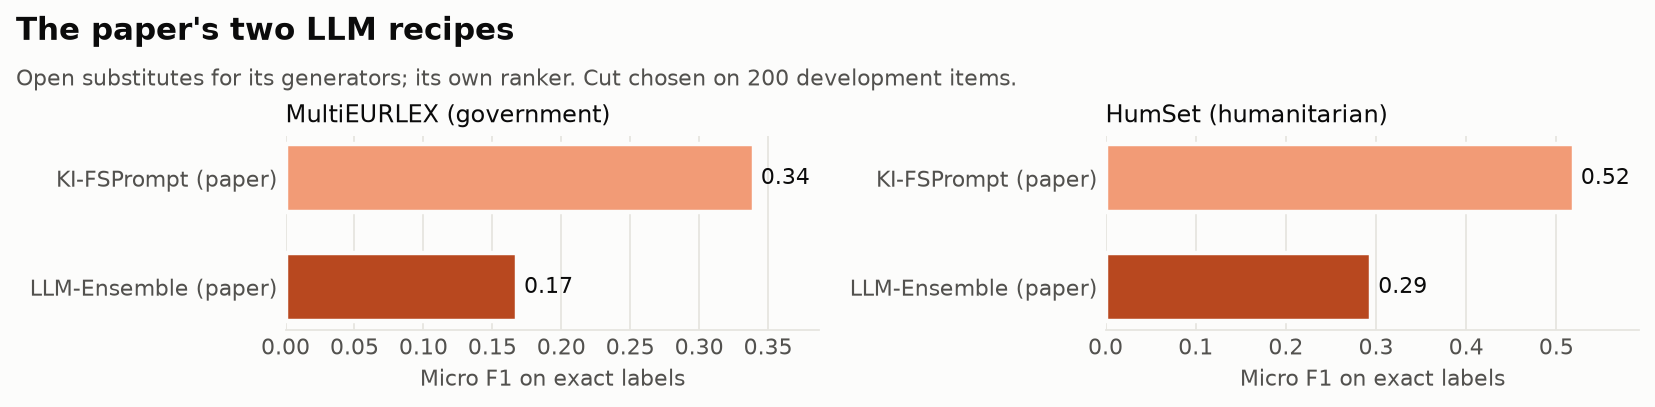

In [4]:
ex.save_results("09_paper_recipes", results)
NAMES = {ex.EURLEX: "MultiEURLEX (government)", ex.HUMSET: "HumSet (humanitarian)"}
panels = {
    NAMES[name]: {
        method: results[name][method]["scores"]["exact"]["f1"] for method in ("llm_ensemble", "ki_fsprompt")
    }
    for name in NAMES
}
path = fg.method_bars(
    panels,
    "Micro F1 on exact labels",
    "The paper's two LLM recipes",
    "Open substitutes for its generators; its own ranker. Cut chosen on 200 development items.",
    FIGURES / "09_paper_recipes.png",
)
Image(str(path), width=900)